[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NadavFireman/Representation-Learning-Midterm-DAE-SimCLR/blob/main/colab_checks.ipynb)

# Checks before colab_partA

Four short checks, on an L4 GPU. Everything goes to a separate Drive folder, `rl_midterm_checks`: nothing in `rl_midterm` or `rl_midterm_experiments` is changed, and TensorBoard shows only these runs.

1. A fine-tune with the new code: do the new metrics (macro F1, AUROC) and the confusion matrix work on the GPU, in 16-mixed?
2. `--retest` on a copy of a finished run: does `test_accuracy` come out the same on the GPU?
3. The plain AE for 30 epochs: does its val k-NN keep rising after epoch 12? (In the final runs it was still rising at epoch 12.)
4. The DAE for 30 epochs, the same way: does it stay with its best epoch near 5?

The fast checks (1, 2) come first, so a problem in the code shows up in minutes. About 1 to 1.5 hours in all.

## Setup
Downloads the repository (or pulls the latest code if it is already here), installs it and checks the GPU. Use an L4 runtime (*Runtime → Change runtime type → L4 GPU*).

In [1]:
import os

REPO = "/content/Representation-Learning-Midterm-DAE-SimCLR"
if not os.path.exists(REPO):
    !git clone https://github.com/NadavFireman/Representation-Learning-Midterm-DAE-SimCLR.git {REPO}
os.chdir(REPO)
!git pull
!git log --oneline -1

Cloning into '/content/Representation-Learning-Midterm-DAE-SimCLR'...
remote: Enumerating objects: 99, done.
remote: Counting objects: 100% (99/99), done.
remote: Compressing objects: 100% (78/78), done.
remote: Total 99 (delta 62), reused 58 (delta 21), pack-reused 0 (from 0)
Receiving objects: 100% (99/99), 551.84 KiB | 19.03 MiB/s, done.
Resolving deltas: 100% (62/62), done.
Already up to date.
4eddb49 (HEAD -> main, origin/main, origin/HEAD) Add colab_checks.ipynb and --num_epochs to check the AE and the new code before colab_partA, and move the earlier notebooks to history/.


In [2]:
%pip install -q -r requirements.txt

import torch
assert torch.cuda.is_available(), "No GPU. Runtime → Change runtime type → L4 GPU, then rerun this cell."
print(torch.cuda.get_device_name(0), "|", os.cpu_count(), "CPU cores")

NVIDIA L4 | 12 CPU cores


## Drive
`MAIN` holds the final runs; the checks only read from it. `CHECKS` is where every check writes.

In [3]:
import shutil
from google.colab import drive

drive.mount("/content/drive")
DRIVE_DIR = "/content/drive/MyDrive/לימודים/תואר שני/שנה ב/סמסטר א/למידת ייצוגים במודלים עמוקים/מטלות/מטלת אמצע"
MAIN = f"{DRIVE_DIR}/rl_midterm"
CHECKS = f"{DRIVE_DIR}/rl_midterm_checks"
os.makedirs(f"{CHECKS}/tb_logs", exist_ok=True)
assert os.path.isdir(f"{MAIN}/tb_logs"), f"no final runs in {MAIN}"
print("reads from:", MAIN)
print("writes to: ", CHECKS)

Mounted at /content/drive
reads from: /content/drive/MyDrive/לימודים/תואר שני/שנה ב/סמסטר א/למידת ייצוגים במודלים עמוקים/מטלות/מטלת אמצע/rl_midterm
writes to:  /content/drive/MyDrive/לימודים/תואר שני/שנה ב/סמסטר א/למידת ייצוגים במודלים עמוקים/מטלות/מטלת אמצע/rl_midterm_checks


In [4]:
# Run this before the checks. The panel keeps updating while train.py runs.
%load_ext tensorboard
%tensorboard --logdir "{CHECKS}/tb_logs"

<IPython.core.display.Javascript object>

## Check 1: the new metrics on the GPU
A fine-tune of the random encoder with 1% of the labels: short (about 3 minutes), and it goes through val, test and the confusion matrix. Its folder should get `confusion_matrix.csv`, `.png` and `most_confused.csv`, and its results `test_f1` and `test_auroc`.

In [5]:
!python train.py --mode finetune --encoder random --label_fraction 0.01 --output_dir "{CHECKS}"

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
EncoderClassifier(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): GELU(approximate='none')
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): GELU(approximate='none')
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=16384, out_features=256, bias

## Check 2: --retest on the GPU
Copies a finished run (the linear probe of the random encoder) from `MAIN` into `CHECKS`, and tests it again. Its first `results.json` is kept as `results_before_retest.json`. If `test_accuracy` changed by more than 0.0005, train.py stops with an error.

In [6]:
RUN = "linear_probe_random_s42_TinyImageNet_1.0_acc"
if not os.path.exists(f"{CHECKS}/tb_logs/{RUN}"):
    shutil.copytree(f"{MAIN}/tb_logs/{RUN}", f"{CHECKS}/tb_logs/{RUN}")  # a copy: the original is not touched
!python train.py --mode linear_probe --encoder random --retest --output_dir "{CHECKS}"

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
I0000 00:00:1795370711.847656    2611 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795370711.919923    2611 cpu_feature_guard.cc:227] This TensorFlow

## Check 3: the AE for 30 epochs
The plain autoencoder (`--noise_level 0`), the same settings as the final run but 30 epochs instead of 12. The kept checkpoint is still the epoch with the best val k-NN.

In [7]:
!python train.py --mode pretrain --noise_level 0 --num_epochs 30 --output_dir "{CHECKS}"

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
DenoisingAutoEncoder(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): GELU(approximate='none')
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): GELU(approximate='none')
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=16384, out_features=256, b

## Check 4: the DAE for 30 epochs
The final DAE (salt and pepper, 50%), also 30 epochs, so the two are compared on the same budget.

In [8]:
!python train.py --mode pretrain --num_epochs 30 --output_dir "{CHECKS}"

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
DenoisingAutoEncoder(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): GELU(approximate='none')
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): GELU(approximate='none')
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=16384, out_features=256, b

## Results
Checks 1 and 2: the files and the numbers. Checks 3 and 4: val k-NN and val loss by epoch, AE against DAE, as a table and a plot. The dotted line is epoch 12, where the final runs stopped.

check 1 files: ['confusion_matrix.csv', 'confusion_matrix.png', 'most_confused.csv', 'results.json']
check 1 results: {'test_loss': 5.3746, 'test_accuracy': 0.0236, 'test_auroc': 0.6203, 'test_f1': 0.013, 'test_precision': 0.0122, 'test_recall': 0.0236, 'test_top5_accuracy': 0.0754}
check 2 test_accuracy: before 0.0749, after 0.0749, new AUROC 0.7702
AE: best val k-NN 0.0753 at epoch 14 of 30; at epoch 12 0.0730; last 0.0722
DAE: best val k-NN 0.1005 at epoch 5 of 30; at epoch 12 0.0818; last 0.0753
epoch   AE k-NN   DAE k-NN
    1   0.0688   0.0796
    2   0.0613   0.0880
    3   0.0628   0.0941
    4   0.0664   0.0987
    5   0.0681   0.1005
    6   0.0689   0.0982
    7   0.0681   0.0928
    8   0.0713   0.0870
    9   0.0727   0.0879
   10   0.0722   0.0844
   11   0.0734   0.0820
   12   0.0730   0.0818
   13   0.0751   0.0844
   14   0.0753   0.0839
   15   0.0752   0.0832
   16   0.0722   0.0851
   17   0.0739   0.0833
   18   0.0733   0.0850
   19   0.0726   0.0829
   20   0.07

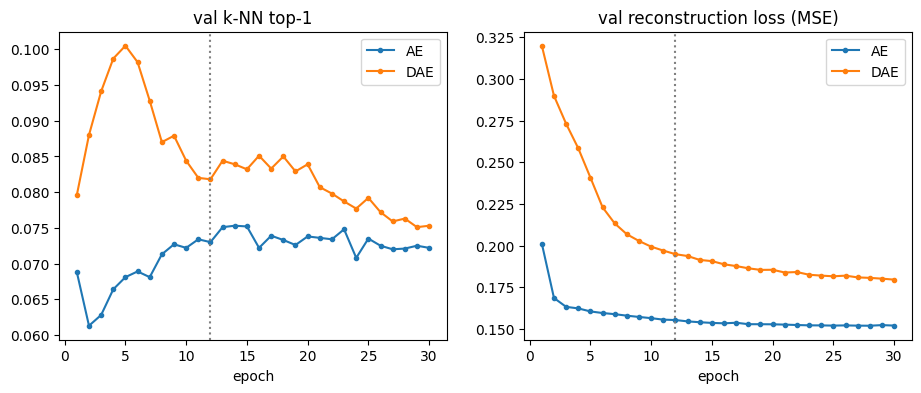

In [9]:
import glob
import json

import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

TB = f"{CHECKS}/tb_logs"

# Checks 1 and 2
ft = f"{TB}/finetune_random_s42_TinyImageNet_0.01_acc"
print("check 1 files:", sorted(f for f in os.listdir(ft) if f.endswith((".csv", ".png", ".json"))))
print("check 1 results:", {k: round(v, 4) for k, v in json.load(open(f"{ft}/results.json")).items()})
before = json.load(open(f"{TB}/{RUN}/results_before_retest.json"))["test_accuracy"]
after = json.load(open(f"{TB}/{RUN}/results.json"))
print(f"check 2 test_accuracy: before {before:.4f}, after {after['test_accuracy']:.4f}, new AUROC {after.get('test_auroc', float('nan')):.4f}")


def curve(run, tag):
    points = {}
    for f in sorted(glob.glob(f"{TB}/{run}/events.out*")):
        acc = EventAccumulator(f, size_guidance={"scalars": 0})
        acc.Reload()
        if tag in acc.Tags()["scalars"]:
            for e in acc.Scalars(tag):
                points.setdefault(e.step, e.value)  # a resumed run logs an epoch twice: keep the first
    return [points[s] for s in sorted(points)]


# Checks 3 and 4
runs = {"AE": "pretrain_dae_TinyImageNet_salt_pepper_0.0_256_s42", "DAE": "pretrain_dae_TinyImageNet_salt_pepper_0.5_256_s42"}
knn = {name: curve(run, "epoch/val_knn_top1") for name, run in runs.items()}
loss = {name: curve(run, "epoch/val_loss") for name, run in runs.items()}
for name, k in knn.items():
    best = max(range(len(k)), key=k.__getitem__)
    print(f"{name}: best val k-NN {k[best]:.4f} at epoch {best + 1} of {len(k)}; at epoch 12 {k[11]:.4f}; last {k[-1]:.4f}")
print("epoch   AE k-NN   DAE k-NN")
for e in range(max(len(k) for k in knn.values())):
    print(f"{e + 1:5d}   " + "   ".join(f"{k[e]:.4f}" if e < len(k) else "   -  " for k in knn.values()))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in runs:
    axes[0].plot(range(1, len(knn[name]) + 1), knn[name], marker=".", label=name)
    axes[1].plot(range(1, len(loss[name]) + 1), loss[name], marker=".", label=name)
for ax, title in zip(axes, ("val k-NN top-1", "val reconstruction loss (MSE)")):
    ax.axvline(12, color="gray", linestyle=":")
    ax.set_xlabel("epoch")
    ax.set_title(title)
    ax.legend()
plt.show()